# 2018 Central Park Squirrel Census — Behavior Analysis in Python

## Overview
This project explores the 2018 Central Park Squirrel Census to find the friendliest areas of the park.
"Friendly" is measured by how often squirrels **approached** the person surveying them.

**The question:** which hectares (survey areas) of Central Park have the friendliest squirrels?

**The answer:** hectare **05E** has the highest share of approaching squirrels (5 of 15, or 33%),
and hectare **07H** had the most approaches overall (6).

## Dataset
- **Source:** [2018 Central Park Squirrel Census – Squirrel Data](https://data.cityofnewyork.us/Environment/2018-Central-Park-Squirrel-Census-Squirrel-Data/vfnx-vebw), NYC Open Data
- **Records:** 3,023 squirrel sightings
- **Columns:** 31

## Tools
Python · pandas · matplotlib · folium (interactive map)

## A note on my Excel version
I analyzed the same census in Excel in a separate project, where I first cleaned the data
(removing duplicates and resolving contradictory records, for 3,018 rows). This notebook works from the
raw 3,023 rows, so some counts differ slightly between the two projects.

## Setup
Importing the libraries for data analysis, charts and mapping.

In [69]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium
import matplotlib.colors as mcolors
from IPython.display import display

print("All good!")


All good!


## Loading the Data
We load the dataset with pandas and take a first look at its structure.

In [70]:
df = pd.read_csv("2018_squirrel_Data.csv")
df.head()

,X,Y,Unique Squirrel ID,Hectare,Shift,Date,Hectare Squirrel Number,Age,Primary Fur Color,Highlight Fur Color,...,Kuks,Quaas,Moans,Tail flags,Tail twitches,Approaches,Indifferent,Runs from,Other Interactions,Lat/Long
0,-73.956134,40.794082,37F-PM-1014-03,37F,PM,10142018,3,NaN,NaN,NaN,...,False,False,False,False,False,False,False,False,NaN,POINT (-73.9561344937861 40.7940823884086)
1,-73.968857,40.783783,21B-AM-1019-04,21B,AM,10192018,4,NaN,NaN,NaN,...,False,False,False,False,False,False,False,False,NaN,POINT (-73.9688574691102 40.7837825208444)
2,-73.974281,40.775534,11B-PM-1014-08,11B,PM,10142018,8,NaN,Gray,NaN,...,False,False,False,False,False,False,False,False,NaN,POINT (-73.97428114848522 40.775533619083)
3,-73.959641,40.790313,32E-PM-1017-14,32E,PM,10172018,14,Adult,Gray,NaN,...,False,False,False,False,False,False,False,True,NaN,POINT (-73.9596413903948 40.7903128889029)
4,-73.970268,40.776213,13E-AM-1017-05,13E,AM,10172018,5,Adult,Gray,Cinnamon,...,False,False,False,False,False,False,False,False,NaN,POINT (-73.9702676472613 40.7762126854894)


The dataset contains 3,023 squirrel sightings across 31 columns, covering location,
physical characteristics and behavior.

## Inspecting the Data
Before any analysis, we check the structure of the dataset: column names, data types and missing values.

In [71]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3023 entries, 0 to 3022
Data columns (total 31 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   X                                           3023 non-null   float64
 1   Y                                           3023 non-null   float64
 2   Unique Squirrel ID                          3023 non-null   str    
 3   Hectare                                     3023 non-null   str    
 4   Shift                                       3023 non-null   str    
 5   Date                                        3023 non-null   int64  
 6   Hectare Squirrel Number                     3023 non-null   int64  
 7   Age                                         2902 non-null   str    
 8   Primary Fur Color                           2968 non-null   str    
 9   Highlight Fur Color                         1937 non-null   str    
 10  Combination of Primary 

Most columns are complete. The gaps are in descriptive fields such as Age, Highlight Fur Color and
Specific Location, which this analysis doesn't use. Columns 26–28 record how each squirrel reacted to
the surveyor (Approaches, Indifferent, Runs from), and those are the focus here.

In [72]:
df.columns[23:29]

Index(['Moans', 'Tail flags', 'Tail twitches', 'Approaches', 'Indifferent',
       'Runs from'],
      dtype='str')

## Behavior Columns
We isolate the three key behavior columns for our analysis:
- **Indifferent**: the squirrel did not react to the surveyor
- **Runs from**: the squirrel ran away
- **Approaches**: the squirrel walked toward the surveyor

In [73]:
df[['Indifferent', 'Runs from', 'Approaches']].head(10)

,Indifferent,Runs from,Approaches
0,False,False,False
1,False,False,False
2,False,False,False
3,False,True,False
4,False,False,False
5,True,False,False
6,False,False,False
7,True,False,False
8,False,False,False
9,True,False,False


## Overall Behavior Counts
We count the total number of squirrels showing each behavior across the whole park.

In [74]:
print("Indifferent:", df['Indifferent'].sum())
print("Runs from:", df['Runs from'].sum())
print("Approaches:", df['Approaches'].sum())


Indifferent: 1454
Runs from: 678
Approaches: 178


Out of 3,023 squirrels observed, 1,454 were indifferent (48%), 678 ran away (22%) and only 178
approached (6%). Most Central Park squirrels are unbothered by people.

These three add up to 2,310, fewer than 3,023: many sightings have no reaction recorded at all, and a few
squirrels were marked with more than one reaction.

## Behavior by Hectare
We group the data by hectare (the grid used to divide Central Park for the census) to see whether
certain areas have noticeably different squirrel behavior.

In [75]:
hectare_behavior = df.groupby('Hectare')[['Indifferent', 'Runs from', 'Approaches']].sum()
hectare_behavior.head(10)


,Indifferent,Runs from,Approaches
Hectare,,,
01A,6,3,0
01B,23,0,1
01C,1,2,1
01D,9,0,0
01E,4,0,1
01F,5,1,1
01G,4,0,2
01H,2,1,1
01I,0,4,0


## Calculating Friendly and Scared Ratios
For each hectare we add up the squirrels with a recorded reaction (`total`), then calculate:
- **friends_ratio**: the share of those squirrels that approached
- **scared_ratio**: the share that ran away

Comparing ratios instead of raw counts keeps busy hectares from winning just because more squirrels were seen there.

In [76]:
hectare_behavior['total'] = (hectare_behavior['Indifferent']
                           + hectare_behavior['Runs from']
                           + hectare_behavior['Approaches'])

hectare_behavior['scared_ratio'] = hectare_behavior['Runs from'] / hectare_behavior['total']
hectare_behavior['friends_ratio'] = hectare_behavior['Approaches'] / hectare_behavior['total']


## Friendliest Hectares
Hectares with only a few sightings can produce extreme ratios by chance (1 approach out of 2 is 50%),
so we keep only hectares with at least 10 recorded reactions.

In [77]:
reliable = hectare_behavior[hectare_behavior['total'] >= 10]

# Preview top friendly hectares
reliable.sort_values('friends_ratio', ascending=False).head(10)


,Indifferent,Runs from,Approaches,total,scared_ratio,friends_ratio
Hectare,,,,,,
05E,8,2,5,15,0.133333,0.333333
35E,6,2,3,11,0.181818,0.272727
14D,12,4,5,21,0.190476,0.238095
16E,8,5,4,17,0.294118,0.235294
07H,18,3,6,27,0.111111,0.222222
32D,8,4,3,15,0.266667,0.200000
02B,7,1,2,10,0.100000,0.200000
36F,4,5,2,11,0.454545,0.181818
11D,7,3,2,12,0.250000,0.166667


Hectare **05E** leads: 5 of its 15 squirrels approached (33%). It is followed by 35E (27%) and 14D (24%).

## Least Friendly Hectares

In [78]:
# Least friendly
reliable.sort_values('friends_ratio', ascending=True).head(10)


,Indifferent,Runs from,Approaches,total,scared_ratio,friends_ratio
Hectare,,,,,,
03B,14,4,0,18,0.222222,0.0
02F,14,1,0,15,0.066667,0.0
03I,12,1,0,13,0.076923,0.0
04E,9,2,0,11,0.181818,0.0
04C,10,3,0,13,0.230769,0.0
04A,10,0,0,10,0.000000,0.0
03H,8,4,0,12,0.333333,0.0
12E,10,4,0,14,0.285714,0.0
09B,13,3,0,16,0.187500,0.0


Many hectares had no approaching squirrels at all, so the bottom of the list is a tie at 0%.
These ten are a sample of those hectares, not a strict ranking.

## Visualizing the Friendliest vs Least Friendly Hectares
Comparing the friendly ratio for the five friendliest and five least friendly hectares.

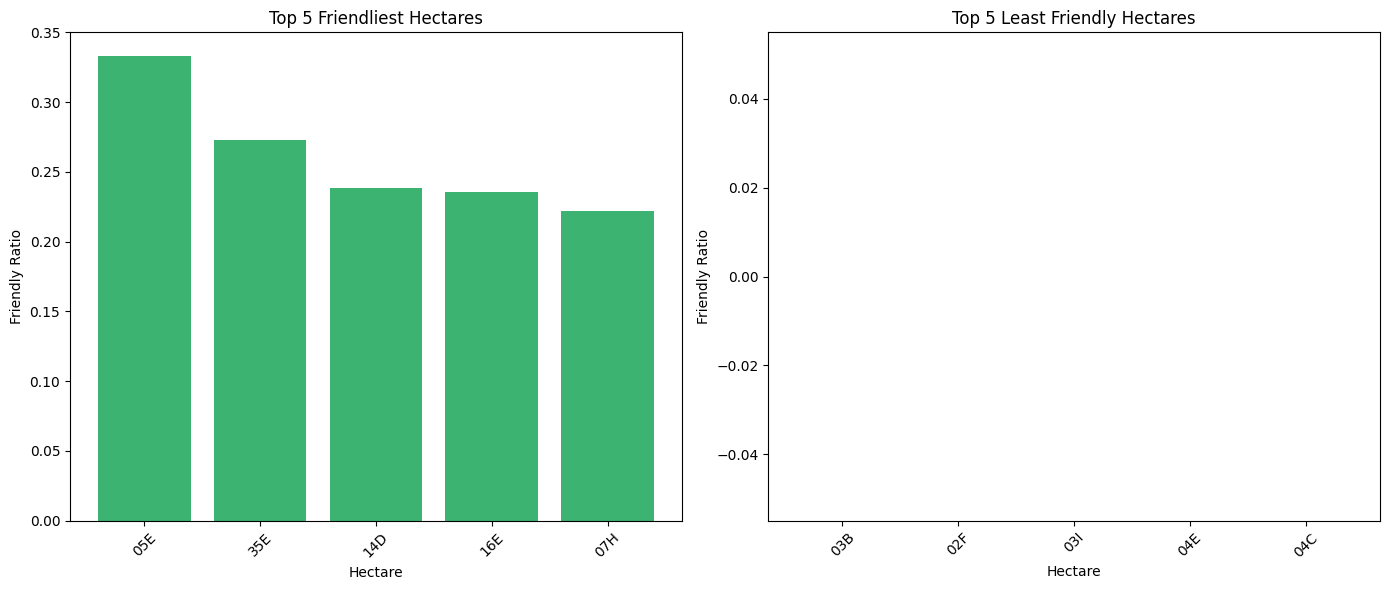

In [79]:
top_friendly = reliable.sort_values('friends_ratio', ascending=False).head(5)
top_unfriendly = reliable.sort_values('friends_ratio', ascending=True).head(5)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

ax1.bar(top_friendly.index, top_friendly['friends_ratio'], color='mediumseagreen')
ax1.set_title('Top 5 Friendliest Hectares')
ax1.set_xlabel('Hectare')
ax1.set_ylabel('Friendly Ratio')
ax1.tick_params(axis='x', rotation=45)

ax2.bar(top_unfriendly.index, top_unfriendly['friends_ratio'], color='tomato')
ax2.set_title('Top 5 Least Friendly Hectares')
ax2.set_xlabel('Hectare')
ax2.set_ylabel('Friendly Ratio')
ax2.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


## Where to Make Squirrel Friends
Finally, we look at which hectares had the most squirrels actively approaching people: the best
spots in Central Park if you want a squirrel encounter.

In [80]:
approaching = df.groupby('Hectare')['Approaches'].sum()
approaching.sort_values(ascending=False).head(10)


Hectare
07H    6
05E    5
03A    5
14D    5
04B    4
20C    4
16E    4
35E    3
40B    3
02C    3
Name: Approaches, dtype: int64

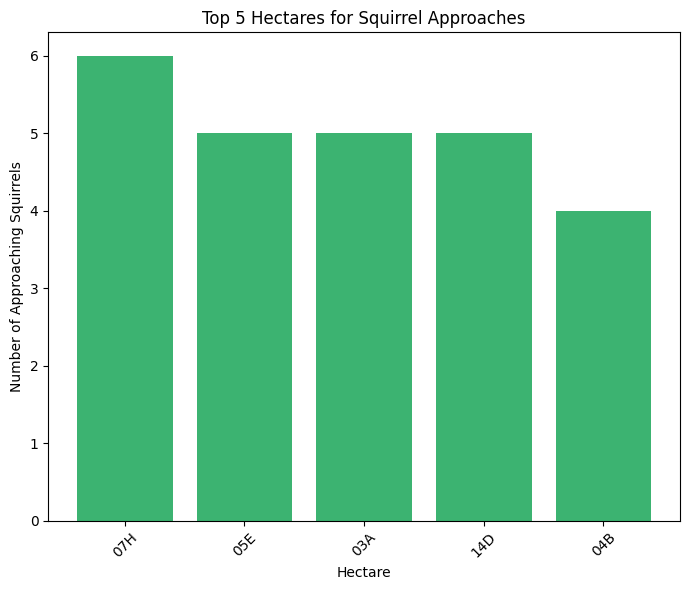

In [81]:
top_approaching = approaching.sort_values(ascending=False).head(5)

plt.figure(figsize=(7, 6))
plt.bar(top_approaching.index, top_approaching.values, color='mediumseagreen')
plt.title('Top 5 Hectares for Squirrel Approaches')
plt.xlabel('Hectare')
plt.ylabel('Number of Approaching Squirrels')
plt.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()


By raw count, **07H** had the most approaches (6), with 05E, 03A and 14D tied at 5. Hectare 05E is
near the top of both lists: it has the highest share of approaching squirrels and the second-most approaches.

## Mapping Friendliness
Each dot is a hectare with at least 10 recorded reactions, placed at the average location of its sightings.
Darker dots are friendlier hectares. Click a dot to see its hectare and friendly ratio.
The map is also saved as `squirrel_map.html`.

In [82]:
# Build map data
hectare_coords = df.groupby('Hectare')[['X', 'Y']].mean()
map_data = hectare_coords.join(reliable[['friends_ratio']])
map_data = map_data.dropna(subset=['friends_ratio'])

# Color scale from 0 to max
norm = mcolors.Normalize(vmin=0, vmax=map_data['friends_ratio'].max())

# Build map
m = folium.Map(location=[40.7851, -73.9683], zoom_start=14)

for idx, row in map_data.iterrows():
    ratio = norm(row['friends_ratio'])
    color = '#00BFFF'

    folium.CircleMarker(
        location=[row['Y'], row['X']],
        radius=8,
        color=color,
        fill=True,
        fill_color=color,
        fill_opacity=float(ratio),
        opacity=float(ratio),
        popup=f"Hectare: {idx} | Friendly Ratio: {row['friends_ratio']:.2f}"
    ).add_to(m)

m.save('squirrel_map.html')
display(m)


## Key Findings
1. **48% of Central Park squirrels were indifferent to people**, 22% ran away and only 6% approached.
2. **Hectare 05E is the friendliest area**: 33% of its squirrels approached the surveyor, the highest share of any hectare with at least 10 recorded reactions.
3. **Hectare 07H had the most approaches** (6), with 05E, 03A and 14D close behind at 5.
4. **Many hectares had no approaching squirrels at all.**

## What This Analysis Can't Tell Us
- **It uses the raw data.** Duplicate sightings and squirrels marked with more than one reaction were not cleaned out, so some totals are slightly off.
- **These are sightings, not individual squirrels.** The same squirrel may have been counted more than once.
- **Small samples.** Even with the 10-reaction minimum, one or two squirrels can move a hectare's ratio a lot.
- **"Approached" stands in for friendly.** A squirrel walking toward you may just want your sandwich.